# COMP4318/5318 作业 2：图像分类

### 小组编号：...；SID1：...；SID2：...；SID3：...；SID4：...

**内部审阅版：额外参考 Baseline。** 保持 Canvas 模板的章节顺序，方便后期整合。此文件不能替代作业必做的「前六周自选算法、MLP、CNN」。本次是 **PathMNIST 病理图像分类**，不是 A1 大米数据。

## 环境与依赖
使用 Python 3.11、NumPy、pandas、Matplotlib、scikit-learn、Jupyter/IPython。以仓库的 `requirements.yaml` 为准。统一随机种子为纯数字 **5318**。

In [1]:
from pathlib import Path
import platform
import time
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn import __version__ as sklearn_version
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import NearestCentroid
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 5318
np.random.seed(SEED)
CLASS_NAMES = {
    0: "Adipose", 1: "Background", 2: "Debris",
    3: "Lymphocytes", 4: "Mucus", 5: "Smooth muscle",
    6: "Normal colon mucosa", 7: "Cancer-associated stroma",
    8: "Colorectal adenocarcinoma epithelium"
}
DATA_RELATIVE = Path("Canvas Sources") / "Assignment2Data-1" / "Assignment2Data"
search_roots = [Path.cwd(), *Path.cwd().parents]
candidate_paths = [
    root / relative
    for root in search_roots
    for relative in (DATA_RELATIVE, Path("Assignment2Data"))
]
DATA_DIR = next((p for p in candidate_paths if (p / "X_train.npy").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Cannot locate Canvas data. Start Jupyter in the repository root "
        "or place the original four .npy files in an Assignment2Data directory."
    )
print("Seed:", SEED, "| Python:", sys.version.split()[0],
      "| NumPy:", np.__version__, "| scikit-learn:", sklearn_version)
print("Machine:", platform.platform())
print("Original Canvas data:", DATA_DIR.resolve())

Seed: 5318 | Python: 3.11.17 | NumPy: 1.26.4 | scikit-learn: 1.5.2
Machine: Linux-6.17.0-1022-azure-x86_64-with-glibc2.39
Original Canvas data: /home/runner/work/5318_A2_Workspace/5318_A2_Workspace/Canvas Sources/Assignment2Data-1/Assignment2Data


## 1. 数据载入、探索与预处理
保留 Canvas 提供的训练与测试集；只从原始训练集按类别分层拆出 80% 的训练部分和 20% 的验证部分。测试集不参与特征设计、调参或模型选择。

In [2]:
# These are the original Canvas training/test partitions, not the public MedMNIST split.
X_train = np.load(DATA_DIR / "X_train.npy", mmap_mode="r", allow_pickle=False)
y_train = np.load(DATA_DIR / "y_train.npy", allow_pickle=False).reshape(-1)
X_test = np.load(DATA_DIR / "X_test.npy", mmap_mode="r", allow_pickle=False)
y_test = np.load(DATA_DIR / "y_test.npy", allow_pickle=False).reshape(-1)

assert X_train.ndim == 4 and X_test.ndim == 4, "Expected NHWC image arrays."
assert X_train.shape[1:] == X_test.shape[1:], "Train/test image dimensions differ."
assert X_train.shape[-1] == 3, "The PathMNIST input should contain three RGB channels."
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert np.issubdtype(y_train.dtype, np.number)
assert np.all(y_train == y_train.astype(int))
assert set(np.unique(y_test)).issubset(set(np.unique(y_train)))
labels = np.sort(np.unique(y_train)).astype(int)
class_labels = [CLASS_NAMES.get(int(k), "Class " + str(k)) for k in labels]
assert len(labels) >= 2, "At least two classes are needed."
print("Training:", X_train.shape, X_train.dtype, "| Test:", X_test.shape, X_test.dtype)
print("Training labels:", labels.tolist(), "| Test retained for final evaluation.")
print("Images are 28x28 RGB if shapes match the assignment description.")

Training: (32000, 28, 28, 3) uint8 | Test: (8000, 28, 28, 3) uint8
Training labels: [0, 1, 2, 3, 4, 5, 6, 7, 8] | Test retained for final evaluation.
Images are 28x28 RGB if shapes match the assignment description.


,class_id,class_name,train_count,train_fraction
0,0,Adipose,3490,0.1091
1,1,Background,3431,0.1072
2,2,Debris,3505,0.1095
3,3,Lymphocytes,3656,0.1142
4,4,Mucus,2950,0.0922
5,5,Smooth muscle,4290,0.1341
6,6,Normal colon mucosa,2728,0.0853
7,7,Cancer-associated stroma,3253,0.1017
8,8,Colorectal adenocarcinoma epithelium,4697,0.1468


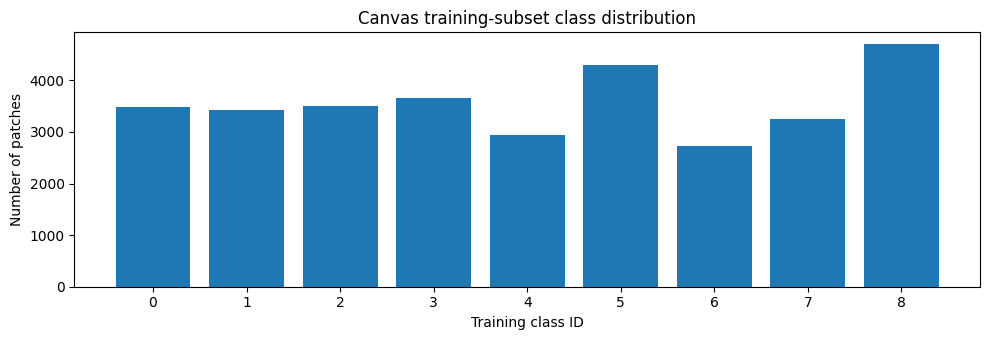

Majority-class training proportion: 0.1468


In [3]:
# Class statistics come only from the supplied training partition.
counts = pd.Series(y_train.astype(int)).value_counts().reindex(labels, fill_value=0)
summary = pd.DataFrame({
    "class_id": labels,
    "class_name": class_labels,
    "train_count": counts.values,
    "train_fraction": (counts.values / len(y_train)).round(4),
})
display(summary)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(summary["class_id"].astype(str), summary["train_count"])
ax.set(xlabel="Training class ID", ylabel="Number of patches",
       title="Canvas training-subset class distribution")
plt.tight_layout()
plt.show()
print("Majority-class training proportion:", round(float(counts.max() / len(y_train)), 4))

### 预处理示例
将像素转为 float32，并根据训练集原始像素范围决定是否除以 255，缩放到 [0,1]。两个 Baseline 均使用展平后的 RGB 特征。这里不引入需要拟合的预处理器，也暂不使用颜色归一化或数据增强，以保持参照标准简单、可复现。

In [4]:
# Image-level re-scaling uses a fixed divisor; no test-set statistics are fitted.
train_min, train_max = float(np.min(X_train)), float(np.max(X_train))
assert np.isfinite(train_min) and np.isfinite(train_max), "Non-finite training pixels."
assert train_min >= 0, "Expected nonnegative RGB intensities."
assert train_max <= 255.0 + 1e-6, "Unexpected pixel range; review scaling."
PIXEL_DIVISOR = 255.0 if train_max > 1.0 + 1e-6 else 1.0
print(f"Train pixel range: [{train_min:.4f}, {train_max:.4f}]; divisor: {PIXEL_DIVISOR}")
all_indices = np.arange(len(y_train))
fit_idx, val_idx = train_test_split(
    all_indices, test_size=0.20, random_state=SEED,
    stratify=y_train.astype(int)
)
assert len(set(fit_idx).intersection(set(val_idx))) == 0
y_fit, y_val = y_train[fit_idx].astype(int), y_train[val_idx].astype(int)
X_fit = np.asarray(X_train[fit_idx], dtype=np.float32).reshape(len(fit_idx), -1) / PIXEL_DIVISOR
X_val = np.asarray(X_train[val_idx], dtype=np.float32).reshape(len(val_idx), -1) / PIXEL_DIVISOR
print(f"Development split: fit={len(fit_idx)}, validation={len(val_idx)}, "
      f"held-out test={len(y_test)}")
print("Flattened features:", X_fit.shape[1])
assert X_fit.min() >= 0 and X_fit.max() <= 1.0 + 1e-6
assert X_val.min() >= 0 and X_val.max() <= 1.0 + 1e-6

Train pixel range: [0.0000, 255.0000]; divisor: 255.0


Development split: fit=25600, validation=6400, held-out test=8000
Flattened features: 2352


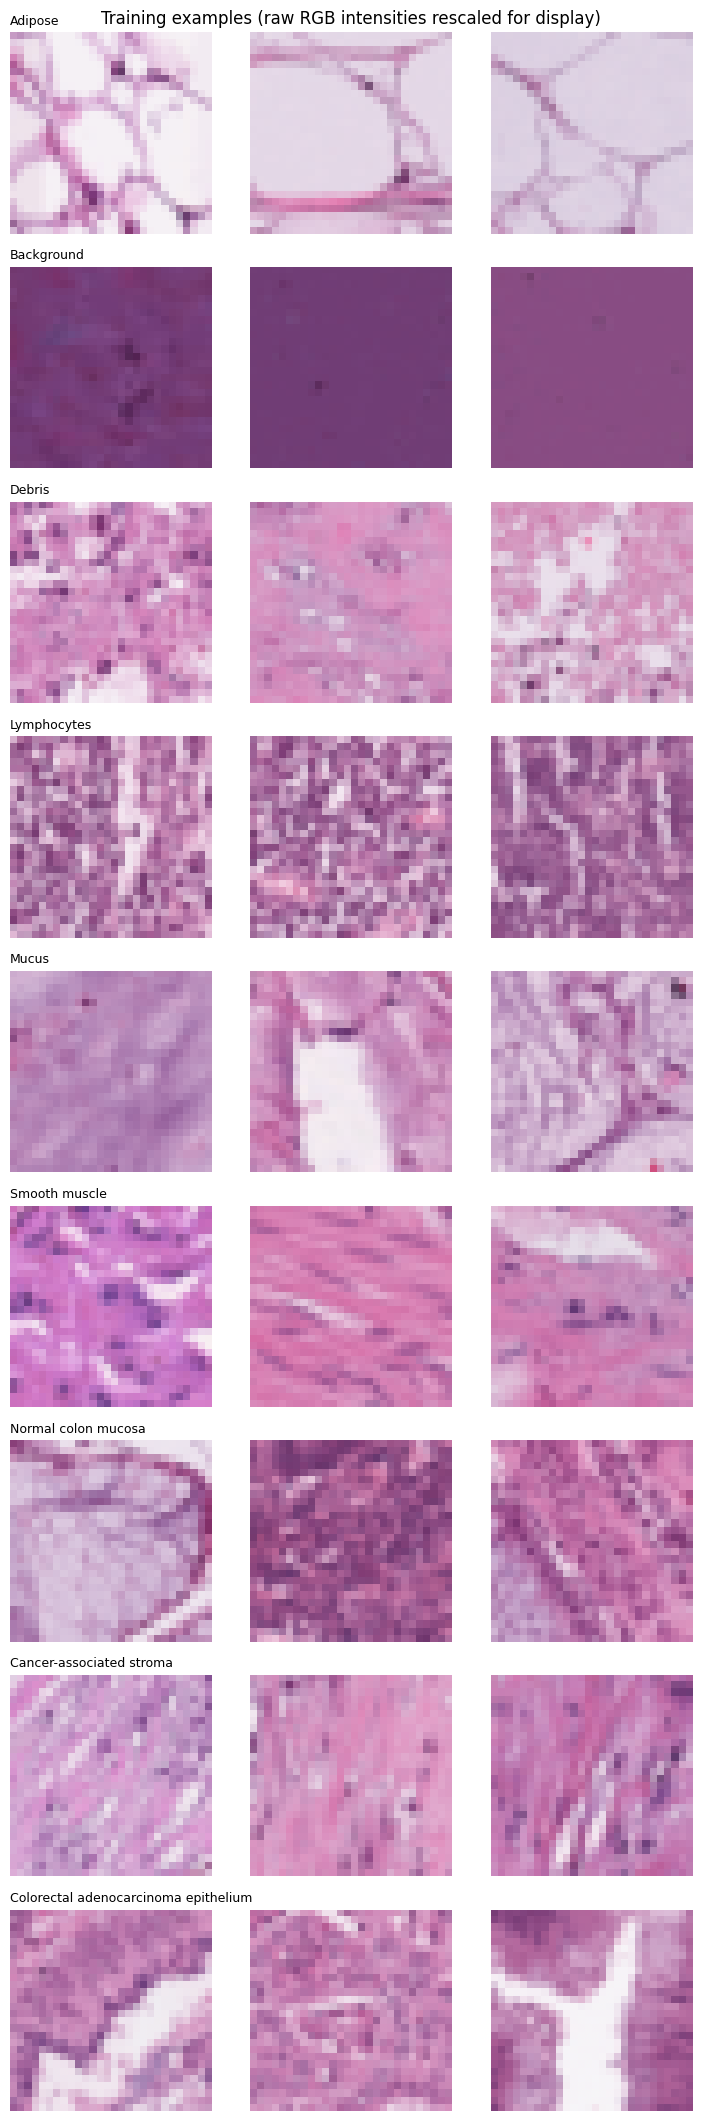

In [5]:
# Show genuine samples from the fit partition, not test examples.
fig, axes = plt.subplots(len(labels), 3, figsize=(7.5, 2.4 * len(labels)))
for row, label in enumerate(labels):
    candidates = fit_idx[y_fit == label]
    chosen = np.random.default_rng(SEED + int(label)).choice(
        candidates, size=min(3, len(candidates)), replace=False
    )
    for column in range(3):
        ax = axes[row, column]
        ax.axis("off")
        if column < len(chosen):
            rgb = np.asarray(X_train[chosen[column]], dtype=np.float32) / PIXEL_DIVISOR
            ax.imshow(np.clip(rgb, 0, 1))
        if column == 0:
            ax.set_title(CLASS_NAMES.get(int(label), "Class " + str(label)),
                         fontsize=9, loc="left")
plt.suptitle("Training examples (raw RGB intensities rescaled for display)")
plt.tight_layout()
plt.show()

## 2. 算法设计与设置
**评分边界：** 此处两个 Baseline 只作参考；课程要求的三种算法分别在独立 Notebook 中实现。

### 前六周自选算法
由负责人在 `Specific_Algorithm_Rememeber_to_change_name.ipynb` 完成，不由此 Baseline 替代。

### 全连接神经网络 MLP
由 `MLP.ipynb` 的负责人完成。

### 卷积神经网络 CNN
由 `CNN.ipynb` 的负责人完成。

### 参考 Baseline 与统一评价规则
**多数类分类器**代表不利用图片信息时的最低参考水平；**最近质心分类器**使用 RGB 像素向量的欧氏距离来识别类别。质心分类器难以处理复杂纹理变形，因此只适合提供朴素参照。

**主要指标为 Macro-F1**，使每个类别在均值中具有同等权重；其次报告 Accuracy、Balanced Accuracy、逐类 Precision/Recall/F1 与混淆矩阵。单独记录训练用时和预测用时，切勿将不同设备上的计时直接当成速度排名。验证集用于开发，测试集仅供最终固定模型使用。

In [6]:
# Shared measurement protocol. Macro-F1 is the primary selection metric.
PRIMARY_METRIC = "macro_f1"
def measure(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels,
                                   average="macro", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred))
    }

def make_baseline(name):
    if name == "Most frequent":
        return DummyClassifier(strategy="most_frequent")
    if name == "Nearest centroid (RGB pixels)":
        return NearestCentroid(metric="euclidean")
    raise ValueError("Unknown baseline: " + name)

BASELINE_NAMES = ["Most frequent", "Nearest centroid (RGB pixels)"]
print("Model-independent protocol:",
      "stratified validation from original training data, seed", SEED,
      "; primary: macro-F1; secondary: accuracy and balanced accuracy.")
print("Train and prediction times use perf_counter; include fit/predict calls, "
      "exclude dataset loading and plotting.")

Model-independent protocol: stratified validation from original training data, seed 5318 ; primary: macro-F1; secondary: accuracy and balanced accuracy.
Train and prediction times use perf_counter; include fit/predict calls, exclude dataset loading and plotting.


## 3. 超参数调整
此处仅比较两种**固定**参考方法，不进行超参数搜索。正式作业的三种模型必须各自调参；MLP 和 CNN 至少调整三种不同的超参数。不能将本节简单对比当成课程要求的调参结果。

### 前六周自选算法
由对应负责人在自己的 Notebook 记录超参数组合、结果与用时。

### 全连接神经网络 MLP
参见 `MLP.ipynb`。

### 卷积神经网络 CNN
参见 `CNN.ipynb`。

### 参考模型的验证集比较（不是调参）

In [7]:
# This cell measures fixed reference algorithms; it is NOT a search for the
# required three assessed algorithms, and makes no decisions using the test set.
validation_records = []
for model_name in BASELINE_NAMES:
    model = make_baseline(model_name)
    fit_start = time.perf_counter()
    model.fit(X_fit, y_fit)
    fit_seconds = time.perf_counter() - fit_start
    pred_start = time.perf_counter()
    y_val_pred = model.predict(X_val)
    prediction_seconds = time.perf_counter() - pred_start
    validation_records.append({
        "model": model_name, **measure(y_val, y_val_pred),
        "fit_seconds": fit_seconds, "prediction_seconds": prediction_seconds
    })
validation_results = pd.DataFrame(validation_records).sort_values(
    "macro_f1", ascending=False
).reset_index(drop=True)
display(validation_results.round(4))
print("No hyperparameters are optimised here; validation is descriptive only.")
print("Any future choice of assessed-model hyperparameters must use this validation split, "
      "not test-set performance.")

,model,accuracy,macro_f1,balanced_accuracy,fit_seconds,prediction_seconds
0,Nearest centroid (RGB pixels),0.4222,0.4051,0.4237,0.0824,0.0670
1,Most frequent,0.1467,0.0284,0.1111,0.0010,0.0001


No hyperparameters are optimised here; validation is descriptive only.
Any future choice of assessed-model hyperparameters must use this validation split, not test-set performance.


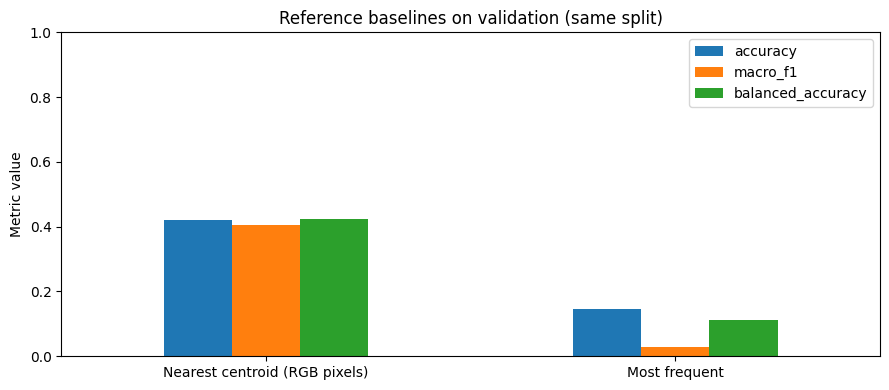

In [8]:
ax = validation_results.set_index("model")[["accuracy", "macro_f1", "balanced_accuracy"]].plot(
    kind="bar", figsize=(9, 4), ylim=(0, 1), rot=0
)
ax.set(title="Reference baselines on validation (same split)",
       ylabel="Metric value", xlabel="")
plt.tight_layout()
plt.show()

## 4. 最终模型
在不依赖第三节调参单元的独立单元中，重新使用整个原始 Canvas 训练集训练固定的参考模型，最后评估官方给出的测试集。跳过验证比较单元，最终单元也应可以正常运行。

### 前六周自选算法
最终整合时引入该负责人独立重新训练的模型。

### 全连接神经网络 MLP
最终整合时引入单独训练的 MLP。

### 卷积神经网络 CNN
最终整合时引入单独训练的 CNN。

### 仅供参照的最终测试结果

In [9]:
# This section is independent of the validation cell: no search object or
# validation-prediction variable is required. Reference configurations are frozen.
# Fit on ALL original training examples after defining the protocol above.
X_full = np.asarray(X_train, dtype=np.float32).reshape(len(X_train), -1) / PIXEL_DIVISOR
X_test_features = np.asarray(X_test, dtype=np.float32).reshape(len(X_test), -1) / PIXEL_DIVISOR
assert X_full.shape[1] == X_test_features.shape[1]
test_records = []
final_predictions = {}
for model_name in BASELINE_NAMES:
    model = make_baseline(model_name)
    start_fit = time.perf_counter()
    model.fit(X_full, y_train.astype(int))
    elapsed_fit = time.perf_counter() - start_fit
    start_predict = time.perf_counter()
    prediction = model.predict(X_test_features)
    elapsed_predict = time.perf_counter() - start_predict
    final_predictions[model_name] = prediction
    test_records.append({
        "model": model_name, "frozen_parameters": str(model.get_params()),
        **measure(y_test.astype(int), prediction),
        "fit_seconds": elapsed_fit,
        "prediction_seconds": elapsed_predict,
        "train_samples": len(y_train), "test_samples": len(y_test),
        "seed": SEED
    })
baseline_test_results = pd.DataFrame(test_records).sort_values(
    "macro_f1", ascending=False
).reset_index(drop=True)
display(baseline_test_results.round(4))
print("The reported test metrics are single-split reference measurements, "
      "not validation tuning scores.")

,model,frozen_parameters,accuracy,macro_f1,balanced_accuracy,fit_seconds,prediction_seconds,train_samples,test_samples,seed
0,Nearest centroid (RGB pixels),"{'metric': 'euclidean', 'shrink_threshold': None}",0.4302,0.4105,0.4325,0.1060,0.0648,32000,8000,5318
1,Most frequent,"{'constant': None, 'random_state': None, 'stra...",0.1468,0.0284,0.1111,0.0009,0.0001,32000,8000,5318


The reported test metrics are single-split reference measurements, not validation tuning scores.


                                      precision    recall  f1-score   support

                             Adipose      0.668     0.960     0.788       873
                          Background      0.456     0.670     0.543       858
                              Debris      0.317     0.268     0.290       877
                         Lymphocytes      0.770     0.435     0.556       914
                               Mucus      0.300     0.577     0.394       737
                       Smooth muscle      0.508     0.283     0.363      1072
                 Normal colon mucosa      0.198     0.199     0.199       682
            Cancer-associated stroma      0.250     0.154     0.190       813
Colorectal adenocarcinoma epithelium      0.397     0.347     0.370      1174

                            accuracy                          0.430      8000
                           macro avg      0.429     0.433     0.410      8000
                        weighted avg      0.441     0.430     

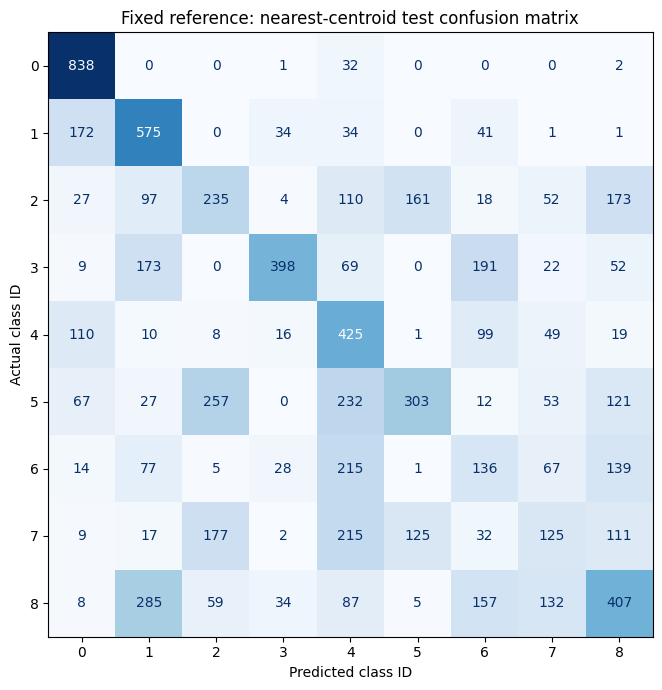

Interpretation caution: neither temporal nor patient-level grouping is verifiable from the supplied arrays alone.
Cross-machine elapsed times are not controlled hardware benchmarks.


In [10]:
# Diagnostic predictions for the fixed nearest-centroid reference.
chosen_name = "Nearest centroid (RGB pixels)"
chosen_predictions = final_predictions[chosen_name]
print(classification_report(
    y_test.astype(int), chosen_predictions, labels=labels,
    target_names=class_labels, zero_division=0, digits=3
))
cm = confusion_matrix(y_test.astype(int), chosen_predictions, labels=labels)
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm, display_labels=[str(i) for i in labels]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title("Fixed reference: nearest-centroid test confusion matrix")
ax.set_xlabel("Predicted class ID")
ax.set_ylabel("Actual class ID")
plt.tight_layout()
plt.show()
print("Interpretation caution: neither temporal nor patient-level grouping "
      "is verifiable from the supplied arrays alone.")
print("Cross-machine elapsed times are not controlled hardware benchmarks.")

### 解释与研究边界
当前为 Canvas 提供的 PathMNIST 小样本版本，不应直接与公开完整数据集的成绩进行数值比较。原始文件未提供患者或切片级组别 ID，按图像分层并不能证明组间独立。28×28 分辨率可能丢失有用形态细节；质心法对染色、亮度变化比较敏感，且无法有效学习复杂纹理。指标与运行时间只对应一次固定划分，不应被当作置信区间。不同硬件的耗时不具备严格可比性。

## 5. AI 使用声明
本 Notebook 的结构、参考 Baseline 代码、评价方案和初步说明由 ChatGPT（OpenAI）协助编写。小组需自行审查并验证真实输出，最终报告及代码声明应根据后续实际 AI 使用情况更新。

**类别标签来源：** Canvas 课程子集，类别名称对照官方 MedMNIST `info.py`（https://github.com/MedMNIST/MedMNIST/blob/main/medmnist/info.py）。